# 02 — Kết quả so sánh mô hình Knowledge Tracing (Chương 4)

So sánh 3 mô hình trên tập **test** SLAM en_es (386,604 interactions), cùng quy trình
chống rò rỉ (ước lượng chỉ trên train, đánh giá trên test) và cùng hàm `evaluate` để
so sánh công bằng:
- **BKT** — Bayesian Knowledge Tracing (baseline xác suất cổ điển).
- **DKT** — Deep Knowledge Tracing (LSTM) — *lõi khoa học của khóa luận*.
- **SAKT** — Self-Attentive Knowledge Tracing (Transformer 1 lớp).

Nguồn số liệu: `ml/models/results.json` (sinh bởi `src/bkt.py`, `src/dkt.py`, `src/sakt.py`).

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

sys.path.append(str(Path.cwd().parent))
from config import MODELS_DIR

results = json.loads((Path(MODELS_DIR) / 'results.json').read_text(encoding='utf-8'))
MODELS = ['bkt', 'dkt', 'sakt']
LABELS = {'bkt': 'BKT', 'dkt': 'DKT', 'sakt': 'SAKT'}
rows = []
for m in MODELS:
    full = results[m]['full']
    rows.append({'Mô hình': LABELS[m], 'AUC': round(full['auc'], 4),
                 'Accuracy': round(full['accuracy'], 4), 'n_test': full['n']})
df = pd.DataFrame(rows).set_index('Mô hình')
df

,AUC,Accuracy,n_test
Mô hình,,,
BKT,0.7228,0.8525,386604
DKT,0.8088,0.8713,386604
SAKT,0.7884,0.8643,386604


## Bảng so sánh (test set)

In [2]:
best = df['AUC'].idxmax()
print('Mô hình tốt nhất theo AUC:', best, f"({df.loc[best,'AUC']:.4f})")
print('DKT vượt BKT:  +%.4f AUC' % (df.loc['DKT','AUC'] - df.loc['BKT','AUC']))
print('DKT vượt SAKT: +%.4f AUC' % (df.loc['DKT','AUC'] - df.loc['SAKT','AUC']))

Mô hình tốt nhất theo AUC: DKT (0.8088)
DKT vượt BKT:  +0.0860 AUC
DKT vượt SAKT: +0.0204 AUC


## Biểu đồ so sánh AUC & Accuracy

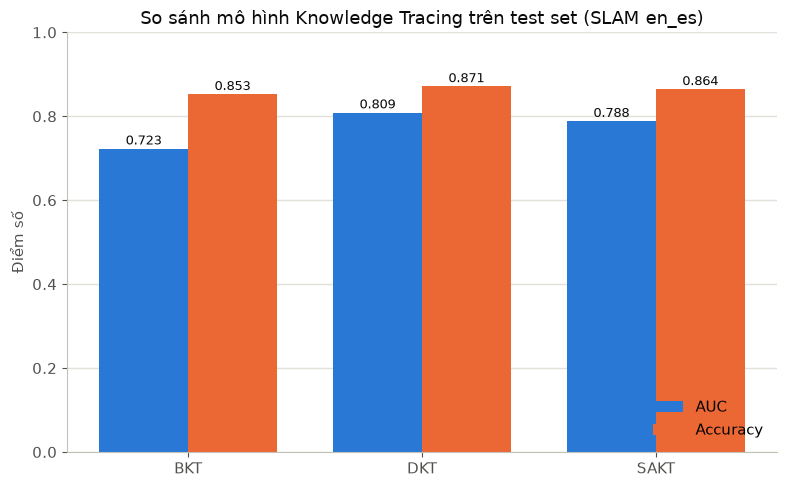

In [3]:
# Palette đã validate (dataviz): blue=AUC, orange=Accuracy
C_AUC, C_ACC = '#2a78d6', '#eb6834'
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

models = df.index.tolist()
x = range(len(models))
w = 0.38
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar([i - w/2 for i in x], df['AUC'], w, label='AUC', color=C_AUC)
b2 = ax.bar([i + w/2 for i in x], df['Accuracy'], w, label='Accuracy', color=C_ACC)

# direct labels (giá trị trên đầu cột)
for bars in (b1, b2):
    for r in bars:
        ax.annotate(f'{r.get_height():.3f}', (r.get_x() + r.get_width()/2, r.get_height()),
                    textcoords='offset points', xytext=(0, 3), ha='center', fontsize=9, color=INK)

ax.set_ylim(0, 1.0)                      # baseline 0 (bar chart trung thực)
ax.set_xticks(list(x)); ax.set_xticklabels(models)
ax.set_ylabel('Điểm số', color=MUTED)
ax.set_title('So sánh mô hình Knowledge Tracing trên test set (SLAM en_es)', color=INK)
ax.yaxis.set_major_locator(mticker.MultipleLocator(0.2))
ax.grid(axis='y', color=GRID, linewidth=1, zorder=0)
ax.set_axisbelow(True)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
for s in ('left', 'bottom'): ax.spines[s].set_color('#c3c2b7')
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

## Nhận xét (Chương 4)

- **DKT (LSTM) tốt nhất** — AUC 0.809, vượt baseline BKT **+0.086** và SAKT **+0.020**.
  Khẳng định giá trị của deep knowledge tracing dạng chuỗi trên dữ liệu SLAM en_es.
- **SAKT > BKT nhưng < DKT**: self-attention (1 lớp) khá hơn Bayesian cổ điển nhưng
  chưa thắng LSTM — mô hình phức tạp hơn không tự động tốt hơn khi dữ liệu/độ sâu hạn
  chế và chuỗi dài nhiều nhiễu. Đây là điểm đáng bàn luận, không phải hạn chế của thí nghiệm.
- **Dữ liệu mất cân bằng** (đúng ~85%) nên **AUC** là chỉ số chính (Accuracy dễ cao ảo).
  Accuracy cùng xu hướng: DKT 0.871 > SAKT 0.864 > BKT 0.853.
- Cả 3 mô hình dùng **chung pipeline** (chống rò rỉ, mask next-step, cùng `evaluate`) →
  chênh lệch phản ánh năng lực mô hình, không do điều kiện đánh giá khác nhau.

> DKT được chọn để phục vụ trong sản phẩm (UC-68); SM-2 (UC-34) là baseline lập lịch
> cổ điển để đối chiếu chính sách ôn tập.